# Import Packages

In [1]:
using DifferentialEquations
using OrdinaryDiffEq
using DiffEqBase
using Sundials
using ODEInterfaceDiffEq
using Plots
using Measures
using CSV
using DataFrames
using EasyFit
using StatsPlots
using LinearAlgebra
using Random
using Distributions
using OrdinaryDiffEq
Random.seed!(145975);
using KernelDensity
using LaTeXStrings
using StatsBase
using JLD2
using HypothesisTests
using LaTeXStrings


In [2]:
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\BayesianInference\\FunctionsBayesInfs.jl")
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\InitalParameterFitPriorDef\\ModelFunctionsAll.jl")
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ComputationalBayesianOED\\FunctionsBayesOED.jl")

redSamples (generic function with 2 methods)

In [3]:
trueP = [48.0, 55.0,0.005911,0.01832,0.042171,0.5365,0.98047,0.991257,0.93335,0.008241,0.9943848,0.001974,   15];

bounds = [[48, 55, 0.001, 0.005, 0.01, 0.1, 0.7, 0.7, 0.7, 0.005, 0.7, 0.0008, 15],
          [48, 55, 0.01, 0.05, 0.08, 0.8, 1.2, 1.2, 1.2, 0.012, 1.2, 0.005, 15]];

InitsY0 = [450, 12599, 226];

boundY0 = [[300, 7000, 100],
           [1000, 25000, 1000]];

# Load Posteriors

In [4]:
posterR1 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ComputationalBayesianOED\\Results\\PosteriorCompetitiveRepression_Rand1_Try1.csv", DataFrame));
posterI1 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ComputationalBayesianOED\\Results\\PosteriorCompetitiveRepression_ID1_Try1.csv", DataFrame));
posterO1 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ComputationalBayesianOED\\Results\\PosteriorCompetitiveRepression_OED1_Try1.csv", DataFrame));

posterR2 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ComputationalBayesianOED\\Results\\PosteriorCompetitiveRepression_Rand2_Try1.csv", DataFrame));
posterI2 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ComputationalBayesianOED\\Results\\PosteriorCompetitiveRepression_ID2_Try1.csv", DataFrame));
posterO2 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ComputationalBayesianOED\\Results\\PosteriorCompetitiveRepression_OED2_Try1.csv", DataFrame));

posterR3 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ComputationalBayesianOED\\Results\\PosteriorCompetitiveRepression_Rand3_Try1.csv", DataFrame));
posterI3 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ComputationalBayesianOED\\Results\\PosteriorCompetitiveRepression_ID3_Try1.csv", DataFrame));
posterO3 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ComputationalBayesianOED\\Results\\PosteriorCompetitiveRepression_OED3_Try2.csv", DataFrame));


In [5]:
posterR1Cut = hcat(posterR1[:,3:12], posterR1[:,14:end]);
posterI1Cut = hcat(posterI1[:,3:12], posterI1[:,14:end]);
posterO1Cut = hcat(posterO1[:,3:12], posterO1[:,14:end]);

posterR2Cut = hcat(posterR2[:,3:12], posterR2[:,14:end]);
posterI2Cut = hcat(posterI2[:,3:12], posterI2[:,14:end]);
posterO2Cut = hcat(posterO2[:,3:12], posterO2[:,14:end]);

posterR3Cut = hcat(posterR3[:,3:12], posterR3[:,14:end]);
posterI3Cut = hcat(posterI3[:,3:12], posterI3[:,14:end]);
posterO3Cut = hcat(posterO3[:,3:12], posterO3[:,14:end]);


# Pyruvate concentrations of experiments

In [6]:
rands = [4.9, 30.4, 10.4];
intus = [1.3, 9, 35];
optis = [1.2, 0.5, 8.3];

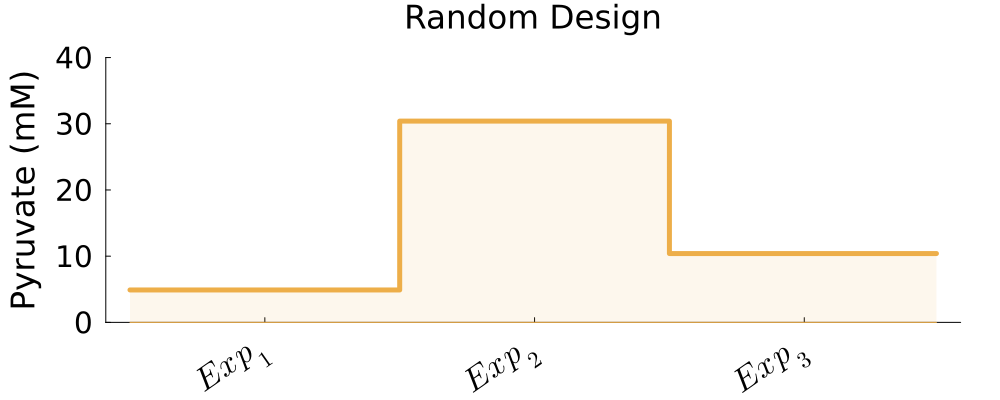

In [7]:
ppr = plot(vcat(collect(0:0.01:1-0.01), collect(1:0.01:2-0.01), collect(2:0.01:3-0.01)), 
        vcat(repeat([rands[1]], 100), repeat([rands[2]], 100), repeat([rands[3]], 100)), linetype=:step, label = "",
        xticks = ([0.5,1.5,2.5], [L"Exp_1",L"Exp_2",L"Exp_3"]), grid = false, linewidth = 5, yrange = (0,40),
        ylabel = "Pyruvate (mM)", margin=8Plots.mm,xtickfont=font(22), ytickfont=font(20), guidefont=font(22), titlefont=font(22),
        xrotation = 35, size = (1000,400), title = "Random Design", colour = "#edae49")
    
    plot!(vcat(collect(0:0.01:1-0.01), collect(1:0.01:2-0.01), collect(2:0.01:3-0.01)), zeros(300), fillrange = vcat(repeat([rands[1]], 100), repeat([rands[2]], 100), repeat([rands[3]], 100)), 
            fillalpha=0.1, label = "", colour = "#edae49")

# savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure4Stuff\\RandomInputDesignProfile.svg")

display(ppr)

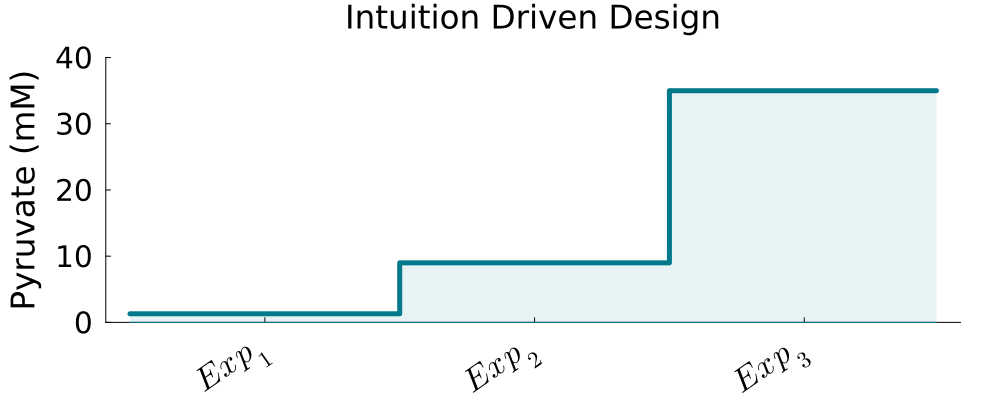

In [8]:
ppr = plot(vcat(collect(0:0.01:1-0.01), collect(1:0.01:2-0.01), collect(2:0.01:3-0.01)), 
        vcat(repeat([intus[1]], 100), repeat([intus[2]], 100), repeat([intus[3]], 100)), linetype=:step, label = "",
        xticks = ([0.5,1.5,2.5], [L"Exp_1",L"Exp_2",L"Exp_3"]), grid = false, linewidth = 5, yrange = (0,40),
        ylabel = "Pyruvate (mM)", margin=8Plots.mm,xtickfont=font(22), ytickfont=font(20), guidefont=font(22), titlefont=font(22),
        xrotation = 35, size = (1000,400), title = "Intuition Driven Design", colour = "#00798cff")
    
    plot!(vcat(collect(0:0.01:1-0.01), collect(1:0.01:2-0.01), collect(2:0.01:3-0.01)), zeros(300), fillrange = vcat(repeat([intus[1]], 100), repeat([intus[2]], 100), repeat([intus[3]], 100)), 
            fillalpha=0.1, label = "", colour = "#00798cff")

# savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure4Stuff\\IntuitionDrivenInputDesignProfile.svg")

display(ppr)


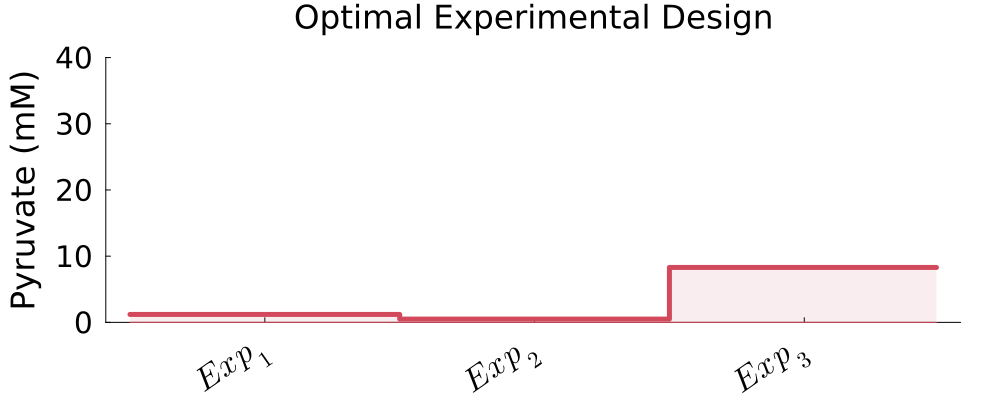

In [9]:
ppr = plot(vcat(collect(0:0.01:1-0.01), collect(1:0.01:2-0.01), collect(2:0.01:3-0.01)), 
        vcat(repeat([optis[1]], 100), repeat([optis[2]], 100), repeat([optis[3]], 100)), linetype=:step, label = "",
        xticks = ([0.5,1.5,2.5], [L"Exp_1",L"Exp_2",L"Exp_3"]), grid = false, linewidth = 5, yrange = (0,40),
        ylabel = "Pyruvate (mM)", margin=8Plots.mm,xtickfont=font(22), ytickfont=font(20), guidefont=font(22), titlefont=font(22),
        xrotation = 35, size = (1000,400), title = "Optimal Experimental Design", colour = "#d1495bff")
    
    plot!(vcat(collect(0:0.01:1-0.01), collect(1:0.01:2-0.01), collect(2:0.01:3-0.01)), zeros(300), fillrange = vcat(repeat([optis[1]], 100), repeat([optis[2]], 100), repeat([optis[3]], 100)), 
            fillalpha=0.1, label = "", colour = "#d1495bff")

# savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure4Stuff\\OptimalInputDesignProfile.svg")

display(ppr)

# Utility Function Values

In [10]:
randsPU = [354.6, 149.2, 42.2];
intusPU = [402.2, 191.4, 97.7];
optisPU = [402.7, 277.7, 134.9];

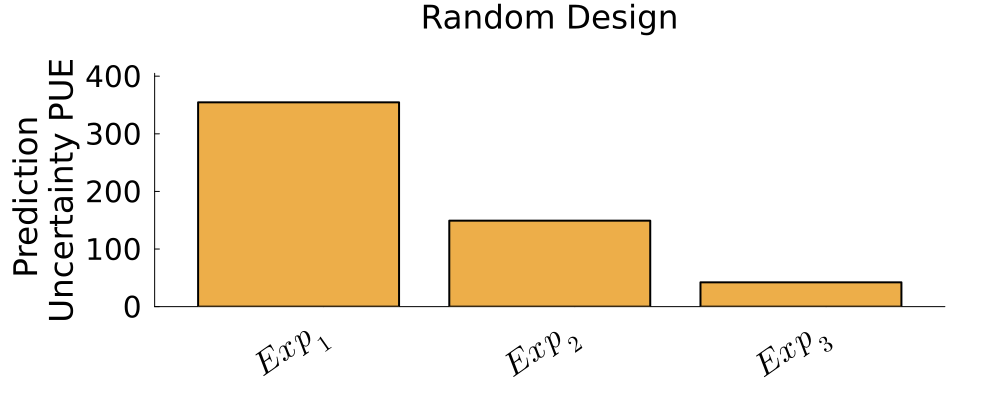

In [12]:
ppr = bar([0.4,1.4,2.4], 
        randsPU, label = "",
        xticks = ([0.5,1.5,2.5], [L"Exp_1",L"Exp_2",L"Exp_3"]), grid = false, linewidth = 2, ylim = (0, 405),
        ylabel = "Prediction \nUncertainty PUE", margin=12Plots.mm,xtickfont=font(22), ytickfont=font(20), guidefont=font(22), titlefont=font(22),
        xrotation = 35, size = (1000,400), title = "Random Design", colour = "#edae49")
    


# savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure4Stuff\\RandomInputDesignUtility.svg")

display(ppr)

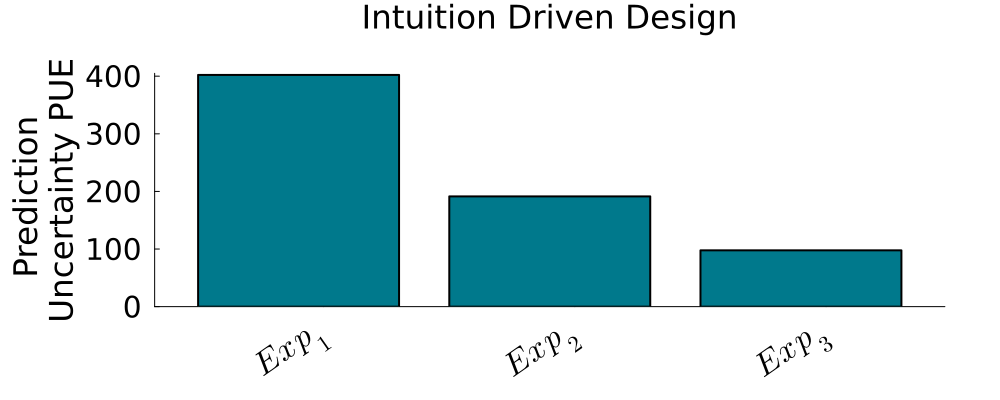

In [13]:
ppr = bar([0.4,1.4,2.4], 
        intusPU, label = "",
        xticks = ([0.5,1.5,2.5], [L"Exp_1",L"Exp_2",L"Exp_3"]), grid = false, linewidth = 2, ylim = (0, 405), 
        ylabel = "Prediction \nUncertainty PUE", margin=12Plots.mm,xtickfont=font(22), ytickfont=font(20), guidefont=font(22), titlefont=font(22),
        xrotation = 35, size = (1000,400), title = "Intuition Driven Design", colour = "#00798cff")
    


# savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure4Stuff\\IntuitionDrivenInputDesignUtility.svg")

display(ppr)

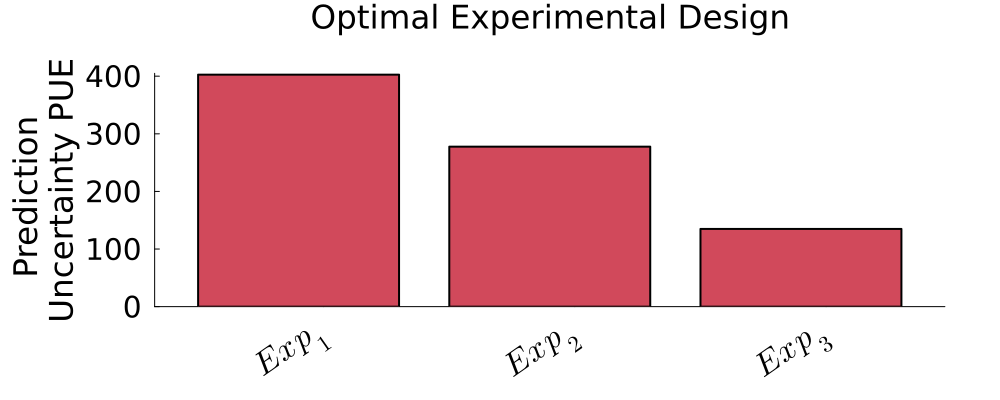

In [14]:
ppr = bar([0.4,1.4,2.4], 
        optisPU, label = "",
        xticks = ([0.5,1.5,2.5], [L"Exp_1",L"Exp_2",L"Exp_3"]), grid = false, linewidth = 2, ylim = (0, 405), 
        ylabel = "Prediction \nUncertainty PUE", margin=12Plots.mm,xtickfont=font(22), ytickfont=font(20), guidefont=font(22), titlefont=font(22),
        xrotation = 35, size = (1000,400), title = "Optimal Experimental Design", colour = "#d1495bff")
    


# savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure4Stuff\\OEDInputDesignUtility.svg")

display(ppr)

# Plot Posteriors Against True Theta

In [15]:
namess = [L"k_{in}", L"k_{PL}", L"k_{b}^N", L"k_{u}^N", L"k_{b}^P", L"k_{u}^P", L"k_{u}^{N+}", L"k_{b}^{N+}", L"k_i", L"k_a", L"NADH_0", L"NAD_0", L"LDH_0"];

In [16]:
trueTH = [0.005911,0.01832,0.042171,0.5365,0.98047,0.991257,0.93335,0.008241,0.9943848,0.001974,450, 12599, 226];

In [17]:
Priors = [Normal(0.0055, 0.00275),
            Normal(0.0275, 0.01375),
            Normal(0.045, 0.0225),
            Normal(0.45, 0.225),
            Normal(0.95, 0.475),
            Normal(0.95, 0.475),
            Normal(0.95, 0.475),
            Normal(0.0085, 0.00425),
            Normal(0.95, 0.475),
            Normal(0.0029, 0.00145),
            Normal(650, 260),
            Normal(16000, 6400),
            Normal(550, 275)];

#### Random Experiments

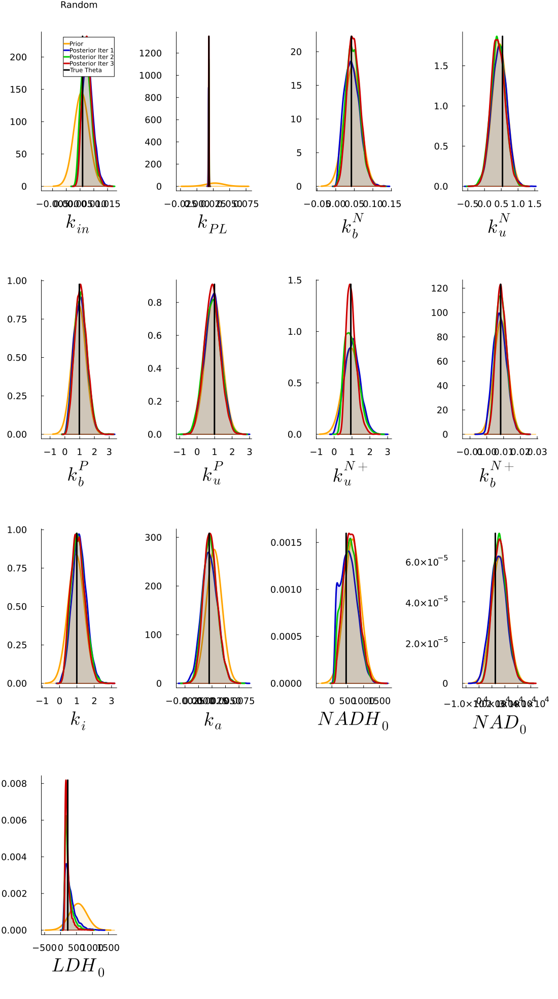

In [193]:
Random.seed!(543265144)
pls = Array{Any}(undef, length(namess));

i = 1

pp1 = plot(Priors[i], linewidth = 3, colour = "orange", label = "Prior", title = "Random")
            pr = rand(Priors[i], 1000)
            plot!(kde(pr).x, zeros(length(kde(pr).x)), fillrange = kde(pr).density, fillalpha=0.1, label = "", colour = "orange")
    plot!(kde(posterR1Cut[:,i]), label = "Posterior Iter 1", grid = false, xlabel = namess[i], linewidth = 3, colour = "blue3")
            plot!(kde(posterR1Cut[:,i]).x, zeros(length(kde(posterR1Cut[:,i]).density)), fillrange = kde(posterR1Cut[:,i]).density, fillalpha=0.1, label = "", colour = "blue3")
    plot!(kde(posterR2Cut[:,i]), label = "Posterior Iter 2", linewidth = 3, colour = "green3")
            plot!(kde(posterR2Cut[:,i]).x, zeros(length(kde(posterR2Cut[:,i]).density)), fillrange = kde(posterR2Cut[:,i]).density, fillalpha=0.1, label = "", colour = "green3")
    plot!(kde(posterR3Cut[:,i]), label = "Posterior Iter 3", linewidth = 3, colour = "red3")
            plot!(kde(posterR3Cut[:,i]).x, zeros(length(kde(posterR3Cut[:,i]).density)), fillrange = kde(posterR3Cut[:,i]).density, fillalpha=0.1, label = "", colour = "red3")
    plot!([trueTH[i], trueTH[i]], [0, maximum(hcat(kde(posterR1Cut[:,i]).density, kde(posterR2Cut[:,i]).density, kde(posterR3Cut[:,i]).density))], label = "True Theta", linewidth = 3, colour = "black")

    pls[1] = pp1

for i in 2:13
    pp1 = plot(Priors[i], linewidth = 3, colour = "orange", label = "")
            pr = rand(Priors[i], 1000)
            plot!(kde(pr).x, zeros(length(kde(pr).x)), fillrange = kde(pr).density, fillalpha=0.1, label = "", colour = "orange")
    plot!(kde(posterR1Cut[:,i]), label = "", grid = false, xlabel = namess[i], linewidth = 3, colour = "blue3")
            plot!(kde(posterR1Cut[:,i]).x, zeros(length(kde(posterR1Cut[:,i]).density)), fillrange = kde(posterR1Cut[:,i]).density, fillalpha=0.1, label = "", colour = "blue3")
    plot!(kde(posterR2Cut[:,i]), label = "", linewidth = 3, colour = "green3")
            plot!(kde(posterR2Cut[:,i]).x, zeros(length(kde(posterR2Cut[:,i]).density)), fillrange = kde(posterR2Cut[:,i]).density, fillalpha=0.1, label = "", colour = "green3")
    plot!(kde(posterR3Cut[:,i]), label = "", linewidth = 3, colour = "red3")
            plot!(kde(posterR3Cut[:,i]).x, zeros(length(kde(posterR3Cut[:,i]).density)), fillrange = kde(posterR3Cut[:,i]).density, fillalpha=0.1, label = "", colour = "red3")
    plot!([trueTH[i], trueTH[i]], [0, maximum(hcat(kde(posterR1Cut[:,i]).density, kde(posterR2Cut[:,i]).density, kde(posterR3Cut[:,i]).density))], label = "", linewidth = 3, colour = "black")

    pls[i] = pp1
end

plot(pls[1],pls[2],pls[3],pls[4], pls[5],pls[6],pls[7],pls[8],pls[9],pls[10],pls[11],pls[12],pls[13], size = (2100,2970),
margin=8Plots.mm,xtickfont=font(12), ytickfont=font(12), guidefont=font(25), titlefont=font(12))

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\SuppFig2Stuff\\PosteriorRandomExpers.svg")

plot(pls[1],pls[2],pls[3],pls[4], pls[5],pls[6],pls[7],pls[8],pls[9],pls[10],pls[11],pls[12],pls[13], size = (1100,1970),
margin=8Plots.mm,xtickfont=font(12), ytickfont=font(12), guidefont=font(25), titlefont=font(12))

#### Intuition Driven Experiments

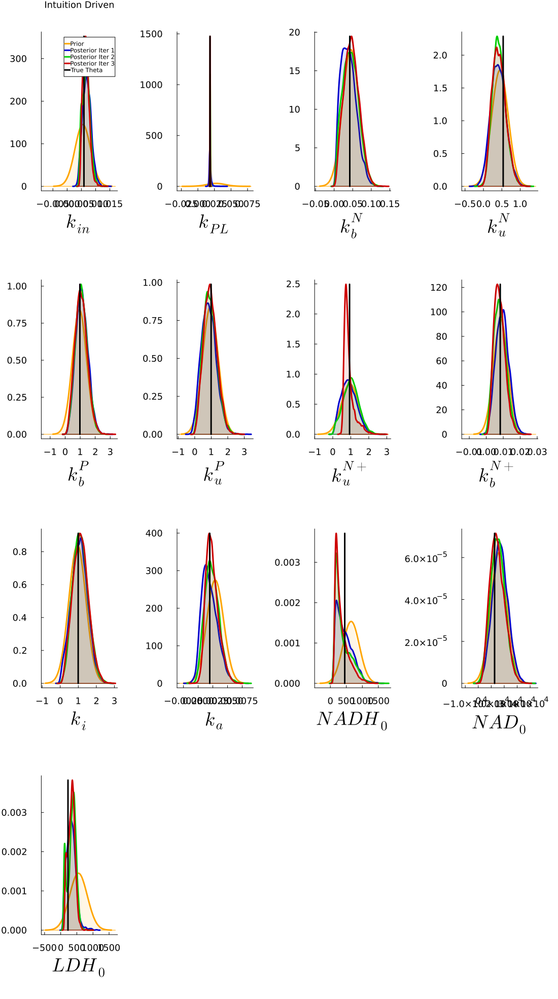

In [194]:
Random.seed!(543265144)
pls = Array{Any}(undef, length(namess));

i = 1

pp1 = plot(Priors[i], linewidth = 3, colour = "orange", label = "Prior", title = "Intuition Driven")
            pr = rand(Priors[i], 1000)
            plot!(kde(pr).x, zeros(length(kde(pr).x)), fillrange = kde(pr).density, fillalpha=0.1, label = "", colour = "orange")
    plot!(kde(posterI1Cut[:,i]), label = "Posterior Iter 1", grid = false, xlabel = namess[i], linewidth = 3, colour = "blue3")
            plot!(kde(posterI1Cut[:,i]).x, zeros(length(kde(posterI1Cut[:,i]).density)), fillrange = kde(posterI1Cut[:,i]).density, fillalpha=0.1, label = "", colour = "blue3")
    plot!(kde(posterI2Cut[:,i]), label = "Posterior Iter 2", linewidth = 3, colour = "green3")
            plot!(kde(posterI2Cut[:,i]).x, zeros(length(kde(posterI2Cut[:,i]).density)), fillrange = kde(posterI2Cut[:,i]).density, fillalpha=0.1, label = "", colour = "green3")
    plot!(kde(posterI3Cut[:,i]), label = "Posterior Iter 3", linewidth = 3, colour = "red3")
            plot!(kde(posterI3Cut[:,i]).x, zeros(length(kde(posterI3Cut[:,i]).density)), fillrange = kde(posterI3Cut[:,i]).density, fillalpha=0.1, label = "", colour = "red3")
    plot!([trueTH[i], trueTH[i]], [0, maximum(hcat(kde(posterI1Cut[:,i]).density, kde(posterI2Cut[:,i]).density, kde(posterI3Cut[:,i]).density))], label = "True Theta", linewidth = 3, colour = "black")

    pls[1] = pp1

for i in 2:13
    pp1 = plot(Priors[i], linewidth = 3, colour = "orange", label = "")
            pr = rand(Priors[i], 1000)
            plot!(kde(pr).x, zeros(length(kde(pr).x)), fillrange = kde(pr).density, fillalpha=0.1, label = "", colour = "orange")
    plot!(kde(posterI1Cut[:,i]), label = "", grid = false, xlabel = namess[i], linewidth = 3, colour = "blue3")
            plot!(kde(posterI1Cut[:,i]).x, zeros(length(kde(posterI1Cut[:,i]).density)), fillrange = kde(posterI1Cut[:,i]).density, fillalpha=0.1, label = "", colour = "blue3")
    plot!(kde(posterI2Cut[:,i]), label = "", linewidth = 3, colour = "green3")
            plot!(kde(posterI2Cut[:,i]).x, zeros(length(kde(posterI2Cut[:,i]).density)), fillrange = kde(posterI2Cut[:,i]).density, fillalpha=0.1, label = "", colour = "green3")
    plot!(kde(posterI3Cut[:,i]), label = "", linewidth = 3, colour = "red3")
            plot!(kde(posterI3Cut[:,i]).x, zeros(length(kde(posterI3Cut[:,i]).density)), fillrange = kde(posterI3Cut[:,i]).density, fillalpha=0.1, label = "", colour = "red3")
    plot!([trueTH[i], trueTH[i]], [0, maximum(hcat(kde(posterI1Cut[:,i]).density, kde(posterI2Cut[:,i]).density, kde(posterI3Cut[:,i]).density))], label = "", linewidth = 3, colour = "black")

    pls[i] = pp1
end

plot(pls[1],pls[2],pls[3],pls[4], pls[5],pls[6],pls[7],pls[8],pls[9],pls[10],pls[11],pls[12],pls[13], size = (2100,2970),
margin=8Plots.mm,xtickfont=font(12), ytickfont=font(12), guidefont=font(25), titlefont=font(12))

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\SuppFig3Stuff\\PosteriorIntuitionDrivenExpers.svg")

plot(pls[1],pls[2],pls[3],pls[4], pls[5],pls[6],pls[7],pls[8],pls[9],pls[10],pls[11],pls[12],pls[13], size = (1100,1970),
margin=8Plots.mm,xtickfont=font(12), ytickfont=font(12), guidefont=font(25), titlefont=font(12))

#### OED

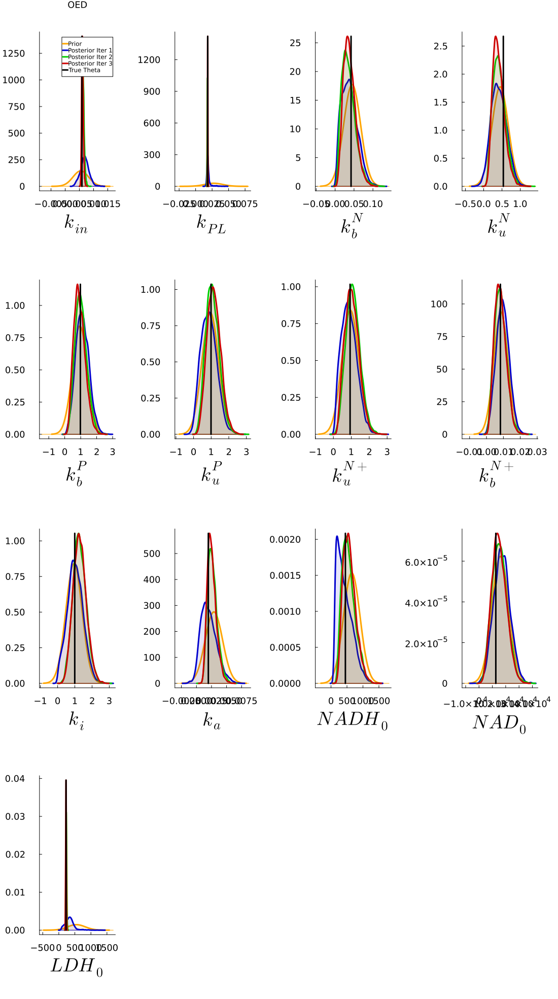

In [195]:
Random.seed!(543265144)
pls = Array{Any}(undef, length(namess));

i = 1

pp1 = plot(Priors[i], linewidth = 3, colour = "orange", label = "Prior", title = "OED")
            pr = rand(Priors[i], 1000)
            plot!(kde(pr).x, zeros(length(kde(pr).x)), fillrange = kde(pr).density, fillalpha=0.1, label = "", colour = "orange")
    plot!(kde(posterO1Cut[:,i]), label = "Posterior Iter 1", grid = false, xlabel = namess[i], linewidth = 3, colour = "blue3")
            plot!(kde(posterO1Cut[:,i]).x, zeros(length(kde(posterO1Cut[:,i]).density)), fillrange = kde(posterO1Cut[:,i]).density, fillalpha=0.1, label = "", colour = "blue3")
    plot!(kde(posterO2Cut[:,i]), label = "Posterior Iter 2", linewidth = 3, colour = "green3")
            plot!(kde(posterO2Cut[:,i]).x, zeros(length(kde(posterO2Cut[:,i]).density)), fillrange = kde(posterO2Cut[:,i]).density, fillalpha=0.1, label = "", colour = "green3")
    plot!(kde(posterO3Cut[:,i]), label = "Posterior Iter 3", linewidth = 3, colour = "red3")
            plot!(kde(posterO3Cut[:,i]).x, zeros(length(kde(posterO3Cut[:,i]).density)), fillrange = kde(posterO3Cut[:,i]).density, fillalpha=0.1, label = "", colour = "red3")
    plot!([trueTH[i], trueTH[i]], [0, maximum(hcat(kde(posterO1Cut[:,i]).density, kde(posterO2Cut[:,i]).density, kde(posterO3Cut[:,i]).density))], label = "True Theta", linewidth = 3, colour = "black")

    pls[1] = pp1

for i in 2:13
    pp1 = plot(Priors[i], linewidth = 3, colour = "orange", label = "")
            pr = rand(Priors[i], 1000)
            plot!(kde(pr).x, zeros(length(kde(pr).x)), fillrange = kde(pr).density, fillalpha=0.1, label = "", colour = "orange")
    plot!(kde(posterO1Cut[:,i]), label = "", grid = false, xlabel = namess[i], linewidth = 3, colour = "blue3")
            plot!(kde(posterO1Cut[:,i]).x, zeros(length(kde(posterO1Cut[:,i]).density)), fillrange = kde(posterO1Cut[:,i]).density, fillalpha=0.1, label = "", colour = "blue3")
    plot!(kde(posterO2Cut[:,i]), label = "", linewidth = 3, colour = "green3")
            plot!(kde(posterO2Cut[:,i]).x, zeros(length(kde(posterO2Cut[:,i]).density)), fillrange = kde(posterO2Cut[:,i]).density, fillalpha=0.1, label = "", colour = "green3")
    plot!(kde(posterO3Cut[:,i]), label = "", linewidth = 3, colour = "red3")
            plot!(kde(posterO3Cut[:,i]).x, zeros(length(kde(posterO3Cut[:,i]).density)), fillrange = kde(posterO3Cut[:,i]).density, fillalpha=0.1, label = "", colour = "red3")
    plot!([trueTH[i], trueTH[i]], [0, maximum(hcat(kde(posterO1Cut[:,i]).density, kde(posterO2Cut[:,i]).density, kde(posterO3Cut[:,i]).density))], label = "", linewidth = 3, colour = "black")

    pls[i] = pp1
end

plot(pls[1],pls[2],pls[3],pls[4], pls[5],pls[6],pls[7],pls[8],pls[9],pls[10],pls[11],pls[12],pls[13], size = (2100,2970),
margin=8Plots.mm,xtickfont=font(12), ytickfont=font(12), guidefont=font(25), titlefont=font(12))

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\SuppFig4Stuff\\PosteriorOEDExpers.svg")

plot(pls[1],pls[2],pls[3],pls[4], pls[5],pls[6],pls[7],pls[8],pls[9],pls[10],pls[11],pls[12],pls[13], size = (1100,1970),
margin=8Plots.mm,xtickfont=font(12), ytickfont=font(12), guidefont=font(25), titlefont=font(12))

# Sample Distance to True Theta

The lower the metric, the better

In [18]:
dPSDR1, dPSDMR1 = dPSD_M(posterR1Cut, trueTH, vcat(bounds[2][3:12], boundY0[2]), vcat(bounds[1][3:12], boundY0[1]));
dPSDI1, dPSDMI1 = dPSD_M(posterI1Cut, trueTH, vcat(bounds[2][3:12], boundY0[2]), vcat(bounds[1][3:12], boundY0[1]));
dPSDO1, dPSDMO1 = dPSD_M(posterO1Cut, trueTH, vcat(bounds[2][3:12], boundY0[2]), vcat(bounds[1][3:12], boundY0[1]));

dPSDR2, dPSDMR2 = dPSD_M(posterR2Cut, trueTH, vcat(bounds[2][3:12], boundY0[2]), vcat(bounds[1][3:12], boundY0[1]));
dPSDI2, dPSDMI2 = dPSD_M(posterI2Cut, trueTH, vcat(bounds[2][3:12], boundY0[2]), vcat(bounds[1][3:12], boundY0[1]));
dPSDO2, dPSDMO2 = dPSD_M(posterO2Cut, trueTH, vcat(bounds[2][3:12], boundY0[2]), vcat(bounds[1][3:12], boundY0[1]));

dPSDR3, dPSDMR3 = dPSD_M(posterR3Cut, trueTH, vcat(bounds[2][3:12], boundY0[2]), vcat(bounds[1][3:12], boundY0[1]));
dPSDI3, dPSDMI3 = dPSD_M(posterI3Cut, trueTH, vcat(bounds[2][3:12], boundY0[2]), vcat(bounds[1][3:12], boundY0[1]));
dPSDO3, dPSDMO3 = dPSD_M(posterO3Cut, trueTH, vcat(bounds[2][3:12], boundY0[2]), vcat(bounds[1][3:12], boundY0[1]));


#### Iter 1

In [196]:
va = vcat(reshape(dPSDR1, 8000*13), reshape(dPSDI1, 8000*13), reshape(dPSDO1, 8000*13));
t = String[]
for j in 1:length(namess)
    for i in 1:8000
        push!(t,namess[j])
    end
end
xa = vcat(t,t,t);

ca = String[]
for i in 1:8000*13
    push!(ca,"1 Rand")
end
for i in 1:8000*13
    push!(ca,"2 ID")
end
for i in 1:8000*13
    push!(ca,"3 OED")
end

pp1 = groupedboxplot(xa, va, group = ca, bar_width = 0.8, palette = :heat, ylabel = L"d_{PSD}", title = "Iter 1",  
margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
size = (1400,600))

;

#### Iter 2

In [197]:
va = vcat(reshape(dPSDR2, 8000*13), reshape(dPSDI2, 8000*13), reshape(dPSDO2, 8000*13));
t = String[]
for j in 1:length(namess)
    for i in 1:8000
        push!(t,namess[j])
    end
end
xa = vcat(t,t,t);

ca = String[]
for i in 1:8000*13
    push!(ca,"1 Rand")
end
for i in 1:8000*13
    push!(ca,"2 ID")
end
for i in 1:8000*13
    push!(ca,"3 OED")
end

pp2 = groupedboxplot(xa, va, group = ca, bar_width = 0.8, palette = :heat, ylabel = L"d_{PSD}", title = "Iter 2",  
margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
size = (1400,600))

;

#### Iter 3

In [198]:
va = vcat(reshape(dPSDR3, 8000*13), reshape(dPSDI3, 8000*13), reshape(dPSDO3, 8000*13));
t = String[]
for j in 1:length(namess)
    for i in 1:8000
        push!(t,namess[j])
    end
end
xa = vcat(t,t,t);

ca = String[]
for i in 1:8000*13
    push!(ca,"1 Rand")
end
for i in 1:8000*13
    push!(ca,"2 ID")
end
for i in 1:8000*13
    push!(ca,"3 OED")
end

pp3 = groupedboxplot(xa, va, group = ca, bar_width = 0.8, palette = :heat, ylabel = L"d_{PSD}", title = "Iter 3",  
margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
size = (1400,600))

;

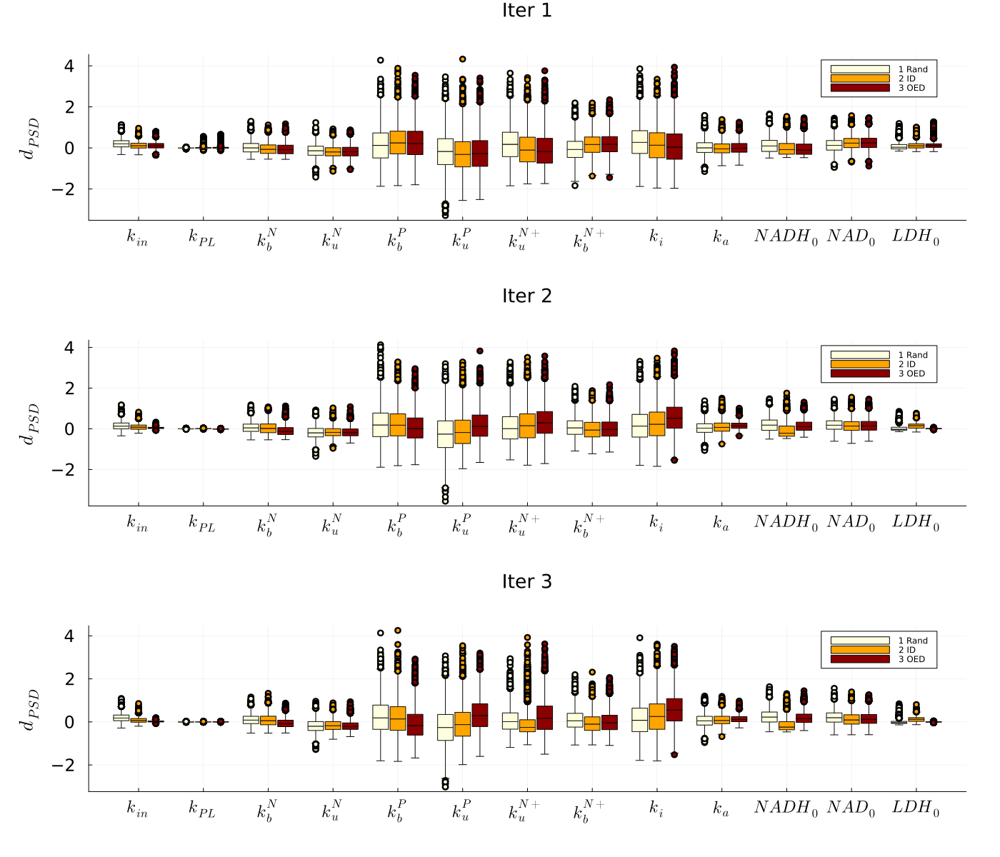

In [199]:
PPP = plot(pp1,pp2,pp3, layout=(3,1), size = (1400,1200))

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\SuppFig5Stuff\\PosteriordPSDPosteriors.svg")

display(PPP)

#### Overall Analysis

In [19]:
sdpsdmR = [sum(dPSDMR1), sum(dPSDMR2), sum(dPSDMR3)];
sdpsdmI = [sum(dPSDMI1), sum(dPSDMI2), sum(dPSDMI3)];
sdpsdmO = [sum(dPSDMO1), sum(dPSDMO2), sum(dPSDMO3)];

In [73]:
sdpsdmO./sdpsdmR

3-element Vector{Float64}:
 0.9919051844170781
 0.8846751440926506
 0.9244460156382255

In [72]:
sdpsdmO./sdpsdmI

3-element Vector{Float64}:
 1.007029413303669
 0.8955259186955273
 0.9622793776038269

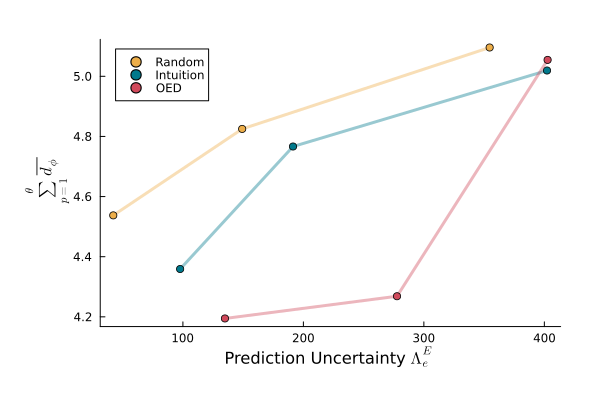

In [53]:
pps = plot(randsPU, sdpsdmR, label = "", grid=false, colour = "#edae49ff", linewidth=3, alpha=0.4, 
            xlabel = "Prediction Uncertainty "*L"$\Lambda^E_e$", ylabel = L"\sum^{\theta}_{p=1} \overline{d_{\phi}}", margin=8Plots.mm)
scatter!(randsPU, sdpsdmR, label = "Random", grid=false, colour = "#edae49ff")

plot!(intusPU, sdpsdmI, label = "", grid=false, colour = "#00798cff", linewidth=3, alpha=0.4)
scatter!(intusPU, sdpsdmI, label = "Intuition", grid=false, colour = "#00798cff")

plot!(optisPU, sdpsdmO, label = "", grid=false, colour = "#d1495bff", linewidth=3, alpha=0.4)
scatter!(optisPU, sdpsdmO, label = "OED", grid=false, colour = "#d1495bff")

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\SuppFig14Stuff\\dPSDM_vs_PredUnc.svg")

display(pps)

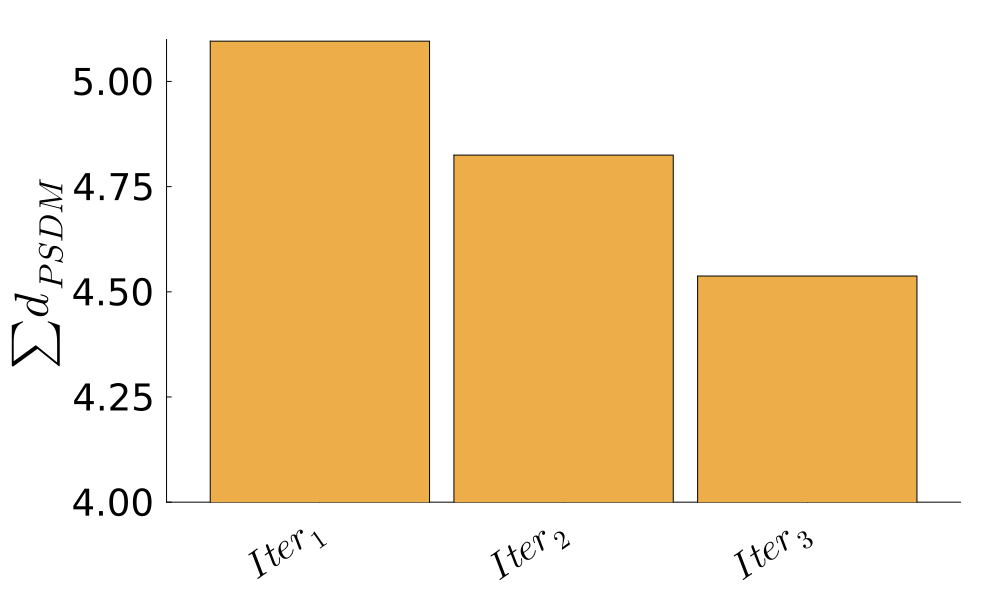

In [23]:
PPR = bar(sdpsdmR , bar_position = :dodge, bar_width=0.9, label = "", colour = "#edae49ff", xticks = (1:3, [L"Iter_1", L"Iter_2", L"Iter_3"]), 
        ylabel = L"\sum d_{PSDM}", linewidth = 1,
        grid = false, margin=8Plots.mm, xtickfont=font(25), ytickfont=font(25), guidefont=font(32), titlefont=font(22),
        xrotation = 35, size = (1000,600), ylim = (4, 5.1))

# savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure4Stuff\\RandomInputDesign_dPSDM.svg")

display(PPR)

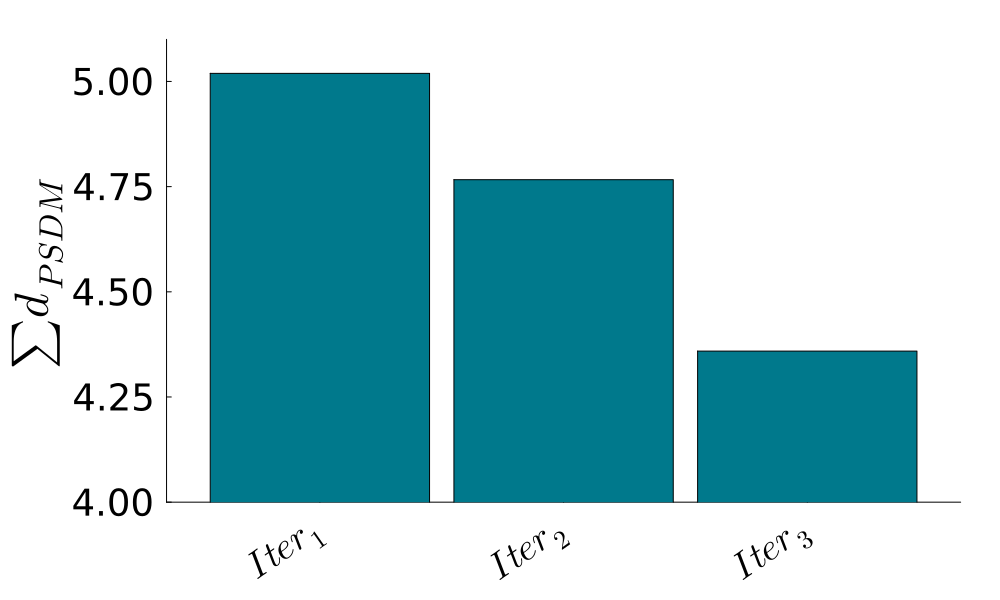

In [21]:
PPR = bar(sdpsdmI , bar_position = :dodge, bar_width=0.9, label = "", colour = "#00798cff", xticks = (1:3, [L"Iter_1", L"Iter_2", L"Iter_3"]), 
        ylabel = L"\sum d_{PSDM}", linewidth = 1,
        grid = false, margin=8Plots.mm, xtickfont=font(25), ytickfont=font(25), guidefont=font(32), titlefont=font(22),
        xrotation = 35, size = (1000,600), ylim = (4, 5.1))

# savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure4Stuff\\IntuitionDrivenInputDesign_dPSDM.svg")

display(PPR)

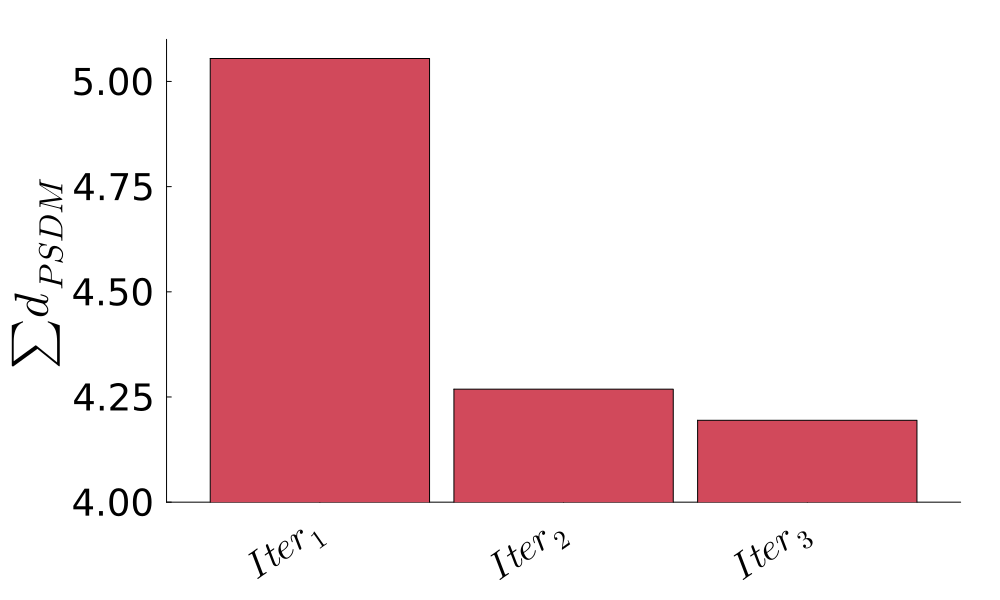

In [22]:
PPR = bar(sdpsdmO , bar_position = :dodge, bar_width=0.9, label = "", colour = "#d1495bff", xticks = (1:3, [L"Iter_1", L"Iter_2", L"Iter_3"]), 
        ylabel = L"\sum d_{PSDM}", linewidth = 1,
        grid = false, margin=8Plots.mm, xtickfont=font(25), ytickfont=font(25), guidefont=font(32), titlefont=font(22),
        xrotation = 35, size = (1000,600), ylim = (4, 5.1))

# savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure4Stuff\\OEDInputDesign_dPSDM.svg")

display(PPR)

# Posterior Covariance Determinant

The lower the metric, the better

In [54]:
# Posteriors
CovsR = [log(det(cov(posterR1Cut))), log(det(cov(posterR2Cut))), log(det(cov(posterR3Cut)))];
CovsI = [log(det(cov(posterI1Cut))), log(det(cov(posterI2Cut))), log(det(cov(posterI3Cut)))];
CovsO = [log(det(cov(posterO1Cut))), log(det(cov(posterO2Cut))), log(det(cov(posterO3Cut)))];

In [78]:
CovsO./CovsR

3-element Vector{Float64}:
 0.962022310867474
 1.4046650764144835
 1.3771055106126349

In [79]:
CovsO./CovsI

3-element Vector{Float64}:
 0.9594381187085961
 1.3057028171648302
 1.2519264670889745

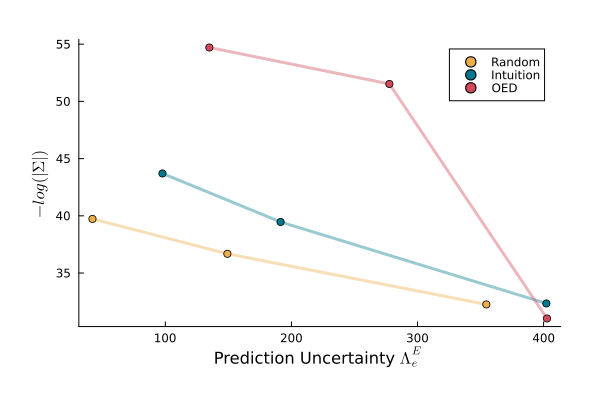

In [58]:
pps = plot(randsPU, -CovsR, label = "", grid=false, colour = "#edae49ff", linewidth=3, alpha=0.4, 
            xlabel = "Prediction Uncertainty "*L"$\Lambda^E_e$", ylabel = L"-log(|\Sigma|)", margin=8Plots.mm)
scatter!(randsPU, -CovsR, label = "Random", grid=false, colour = "#edae49ff")

plot!(intusPU, -CovsI, label = "", grid=false, colour = "#00798cff", linewidth=3, alpha=0.4)
scatter!(intusPU, -CovsI, label = "Intuition", grid=false, colour = "#00798cff")

plot!(optisPU, -CovsO, label = "", grid=false, colour = "#d1495bff", linewidth=3, alpha=0.4)
scatter!(optisPU, -CovsO, label = "OED", grid=false, colour = "#d1495bff")

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\SuppFig14Stuff\\Cov_vs_PredUnc.svg")

display(pps)

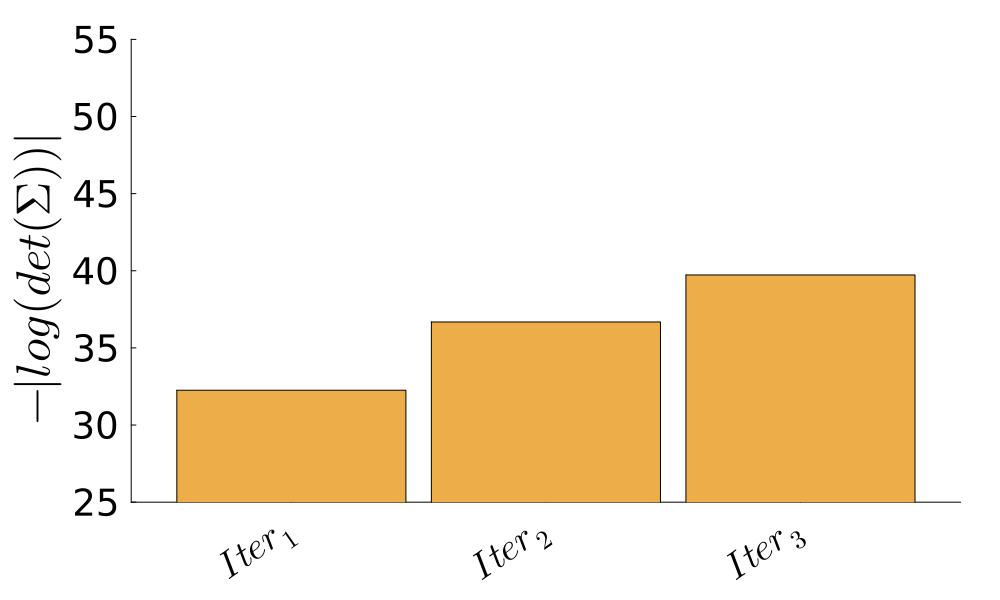

In [253]:
PPR = bar(-CovsR , bar_position = :dodge, bar_width=0.9, label = "", colour = "#edae49ff", xticks = (1:3, [L"Iter_1", L"Iter_2", L"Iter_3"]), 
        ylabel = L"-|log(det(\Sigma))|", linewidth = 1,
        grid = false, margin=8Plots.mm, xtickfont=font(25), ytickfont=font(25), guidefont=font(32), titlefont=font(22),
        xrotation = 35, size = (1000,600), ylim=(25, 55))

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure4Stuff\\RandomInputDesign_COV.svg")

display(PPR)

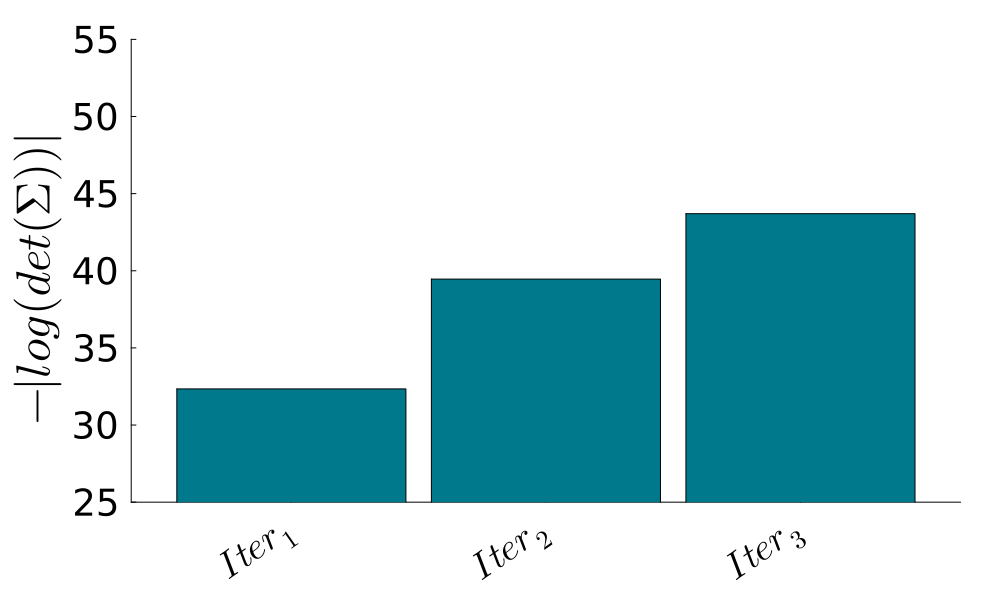

In [254]:
PPR = bar(-CovsI , bar_position = :dodge, bar_width=0.9, label = "", colour = "#00798cff", xticks = (1:3, [L"Iter_1", L"Iter_2", L"Iter_3"]), 
        ylabel = L"-|log(det(\Sigma))|", linewidth = 1,
        grid = false, margin=8Plots.mm, xtickfont=font(25), ytickfont=font(25), guidefont=font(32), titlefont=font(22),
        xrotation = 35, size = (1000,600), ylim=(25, 55))

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure4Stuff\\IntuitionDrivenInputDesign_COV.svg")

display(PPR)

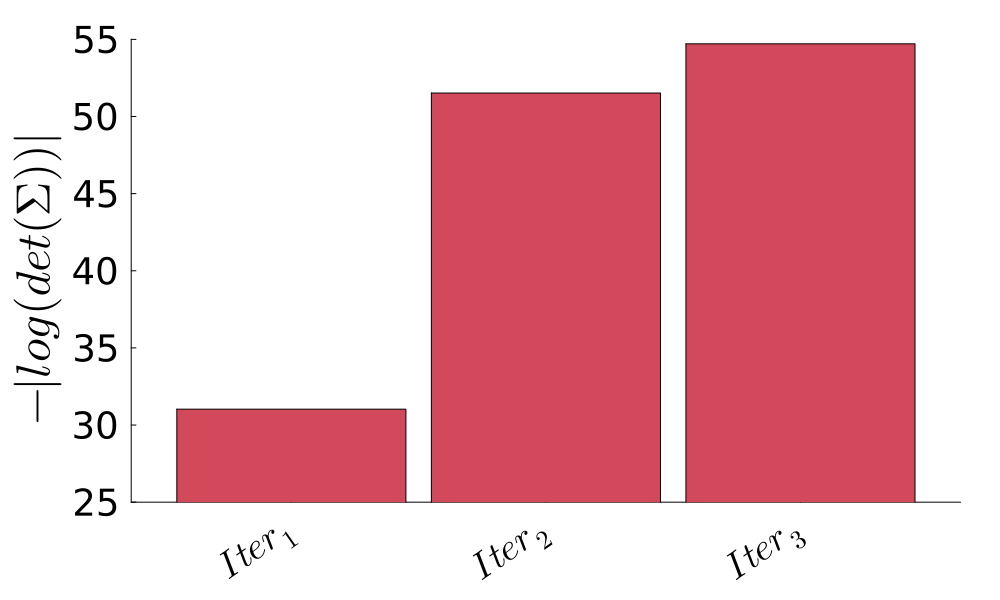

In [255]:
PPR = bar(-CovsO , bar_position = :dodge, bar_width=0.9, label = "", colour = "#d1495bff", xticks = (1:3, [L"Iter_1", L"Iter_2", L"Iter_3"]), 
        ylabel = L"-|log(det(\Sigma))|", linewidth = 1,
        grid = false, margin=8Plots.mm, xtickfont=font(25), ytickfont=font(25), guidefont=font(32), titlefont=font(22),
        xrotation = 35, size = (1000,600), ylim=(25, 55))

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure4Stuff\\OEDInputDesign_COV.svg")

display(PPR)

# Entropy Difference

The higher the metric, the better

In [59]:
mes = [0.0055, 0.0275, 0.045, 0.45, 0.95, 0.95, 0.95, 0.0085, 0.95, 0.0029, 650, 16000, 550];
sts = [0.00275, 0.01375, 0.0225, 0.225, 0.475, 0.475, 0.475, 0.00425, 0.475, 0.00145, 260, 6400, 275];

HPrior = entropy(MvNormal(mes, Diagonal(ones(13)).*sts));


In [60]:
H_U_Post = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ComputationalBayesianOED\\Results\\EntroPosters.jld")["H_U_Post"];
H_L_Post = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ComputationalBayesianOED\\Results\\EntroPosters.jld")["H_L_Post"];
H_Post = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ComputationalBayesianOED\\Results\\EntroPosters.jld")["H_Post"];

In [61]:
H_gain = Array{Any,2}(undef,3,3);
[H_gain[j,i] = HPrior-H_Post[j,i] for i in 1:3 for j in 1:3];


In [81]:
H_gain[:,3]./H_gain[:,1]

3-element Vector{Float64}:
 1.0450731029250666
 1.298362997710348
 1.285929167718528

In [82]:
H_gain[:,3]./H_gain[:,2]

3-element Vector{Float64}:
 0.9998321861081328
 1.2108819932747923
 1.1722462126907582

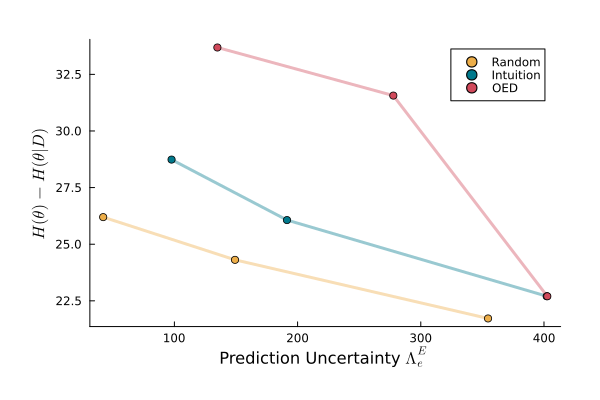

In [65]:
pps = plot(randsPU, H_gain[:,1], label = "", grid=false, colour = "#edae49ff", linewidth=3, alpha=0.4, 
            xlabel = "Prediction Uncertainty "*L"$\Lambda^E_e$", ylabel = L"H(\theta)-H(\theta | D)", margin=8Plots.mm)
scatter!(randsPU, H_gain[:,1], label = "Random", grid=false, colour = "#edae49ff")

plot!(intusPU, H_gain[:,2], label = "", grid=false, colour = "#00798cff", linewidth=3, alpha=0.4)
scatter!(intusPU, H_gain[:,2], label = "Intuition", grid=false, colour = "#00798cff")

plot!(optisPU, H_gain[:,3], label = "", grid=false, colour = "#d1495bff", linewidth=3, alpha=0.4)
scatter!(optisPU, H_gain[:,3], label = "OED", grid=false, colour = "#d1495bff")

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\SuppFig14Stuff\\Entro_vs_PredUnc.svg")

display(pps)

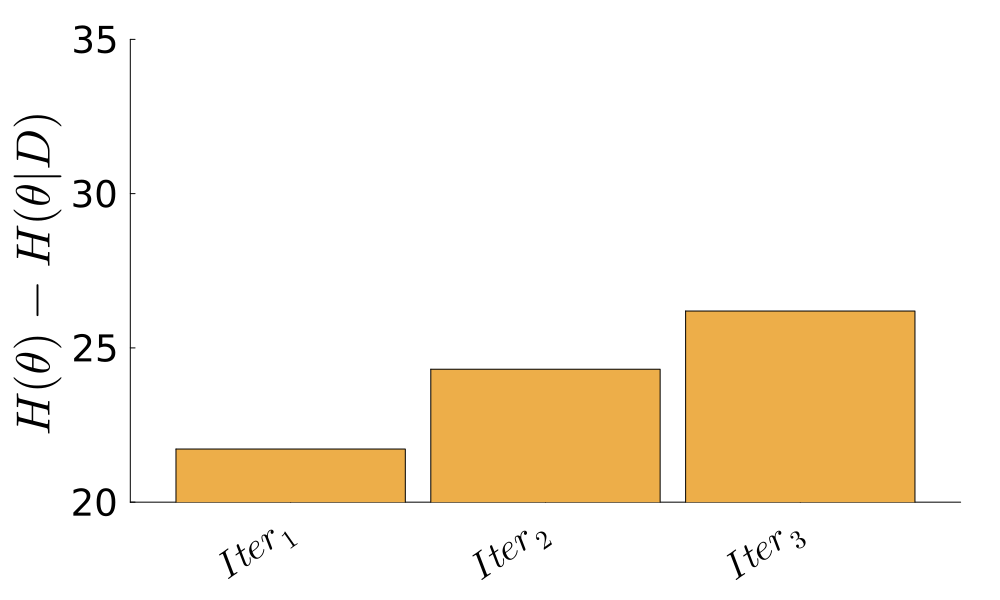

In [274]:
PPR = bar(H_gain[:,1] , bar_position = :dodge, bar_width=0.9, label = "", colour = "#edae49ff", xticks = (1:3, [L"Iter_1", L"Iter_2", L"Iter_3"]), 
        ylabel = L"H(\theta)-H(\theta | D)", linewidth = 1,
        grid = false, margin=8Plots.mm, xtickfont=font(25), ytickfont=font(25), guidefont=font(32), titlefont=font(22),
        xrotation = 35, size = (1000,600), ylim = (20, 35))

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure4Stuff\\RandomInputDesign_Entro.svg")

display(PPR)

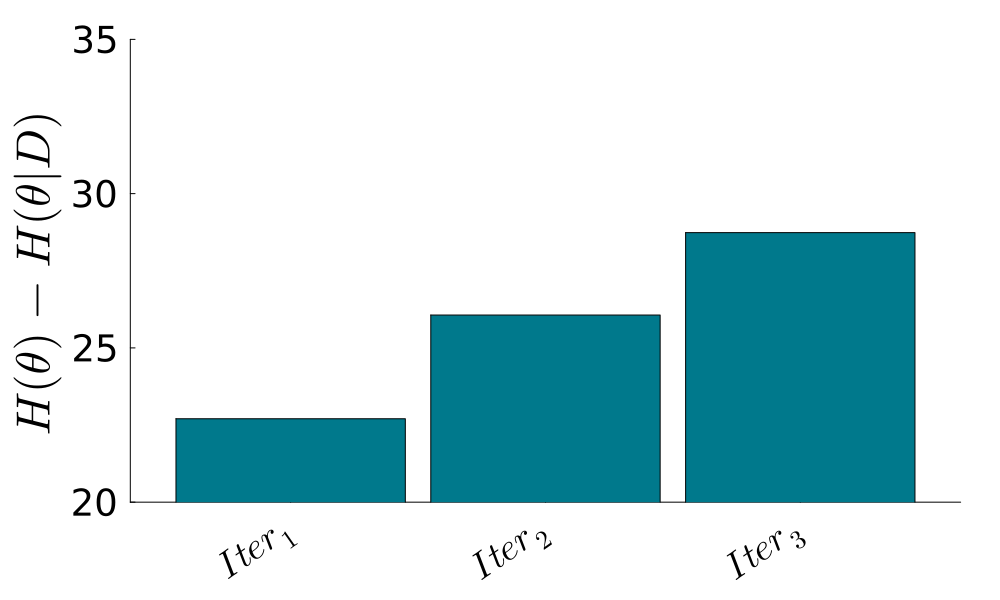

In [275]:
PPR = bar(H_gain[:,2] , bar_position = :dodge, bar_width=0.9, label = "", colour = "#00798cff", xticks = (1:3, [L"Iter_1", L"Iter_2", L"Iter_3"]), 
        ylabel = L"H(\theta)-H(\theta | D)", linewidth = 1,
        grid = false, margin=8Plots.mm, xtickfont=font(25), ytickfont=font(25), guidefont=font(32), titlefont=font(22),
        xrotation = 35, size = (1000,600), ylim = (20, 35))

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure4Stuff\\IntuitionDrivenInputDesign_Entro.svg")

display(PPR)

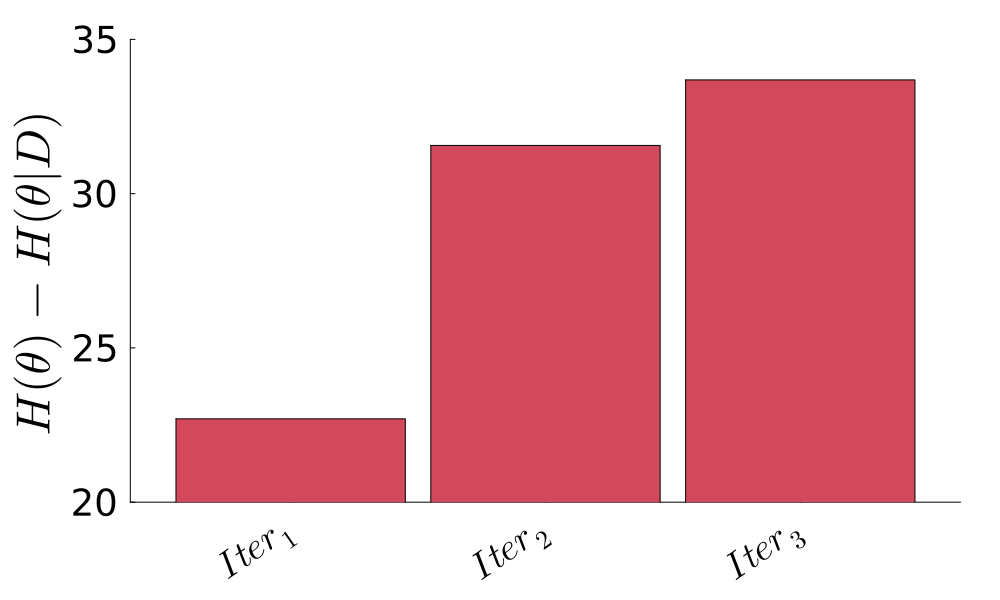

In [276]:
PPR = bar(H_gain[:,3] , bar_position = :dodge, bar_width=0.9, label = "", colour = "#d1495bff", xticks = (1:3, [L"Iter_1", L"Iter_2", L"Iter_3"]), 
        ylabel = L"H(\theta)-H(\theta | D)", linewidth = 1,
        grid = false, margin=8Plots.mm, xtickfont=font(25), ytickfont=font(25), guidefont=font(32), titlefont=font(22),
        xrotation = 35, size = (1000,600), ylim = (20, 35))

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure4Stuff\\OEDInputDesign_Entro.svg")

display(PPR)